# Stage 7: figures

**What this stage does:** draws the network pictures and the degree distributions used in the report.

**Reads:** `data/processed/nodes_<format>.csv`, `edges_<format>.csv` and `outputs/tables/node_metrics_<format>.csv`
**Writes:** `outputs/figures/network_<format>.png`, `network_comparison.png` and `degree_distributions.png`

In [1]:
%run ./library/lib_00_settings.ipynb
%run ./library/lib_04_network_building.ipynb
%run ./library/lib_06_figures.ipynb
stage_log = get_stage_logger("07_figures")

In [2]:
graphs_by_format, measures_by_format = {}, {}
for format_name in FORMATS:
    file_tag = FORMAT_FILE_TAG[format_name]
    graphs_by_format[format_name] = load_format_graph(format_name)
    measures_by_format[format_name] = read_table(TABLES_FOLDER / f"node_metrics_{file_tag}.csv")
    save_single_network_figure(graphs_by_format[format_name], measures_by_format[format_name], format_name,
                               FIGURES_FOLDER / f"network_{file_tag}.png")
    stage_log.info("saved network_%s.png", file_tag)
save_comparison_figure(graphs_by_format, measures_by_format, FIGURES_FOLDER / "network_comparison.png")
save_degree_distribution_figure(measures_by_format, FIGURES_FOLDER / "degree_distributions.png")
stage_log.info("saved network_comparison.png and degree_distributions.png")

2026-11-19 18:05:17,602 INFO partnerships.07_figures: saved network_test.png


2026-11-19 18:05:17,944 INFO partnerships.07_figures: saved network_odi.png


2026-11-19 18:05:18,274 INFO partnerships.07_figures: saved network_t20i.png


2026-11-19 18:05:20,062 INFO partnerships.07_figures: saved network_comparison.png and degree_distributions.png


### Quick look

The network pictures are large files, so we only show the small degree-distribution figure here. The networks
are in `outputs/figures/`.

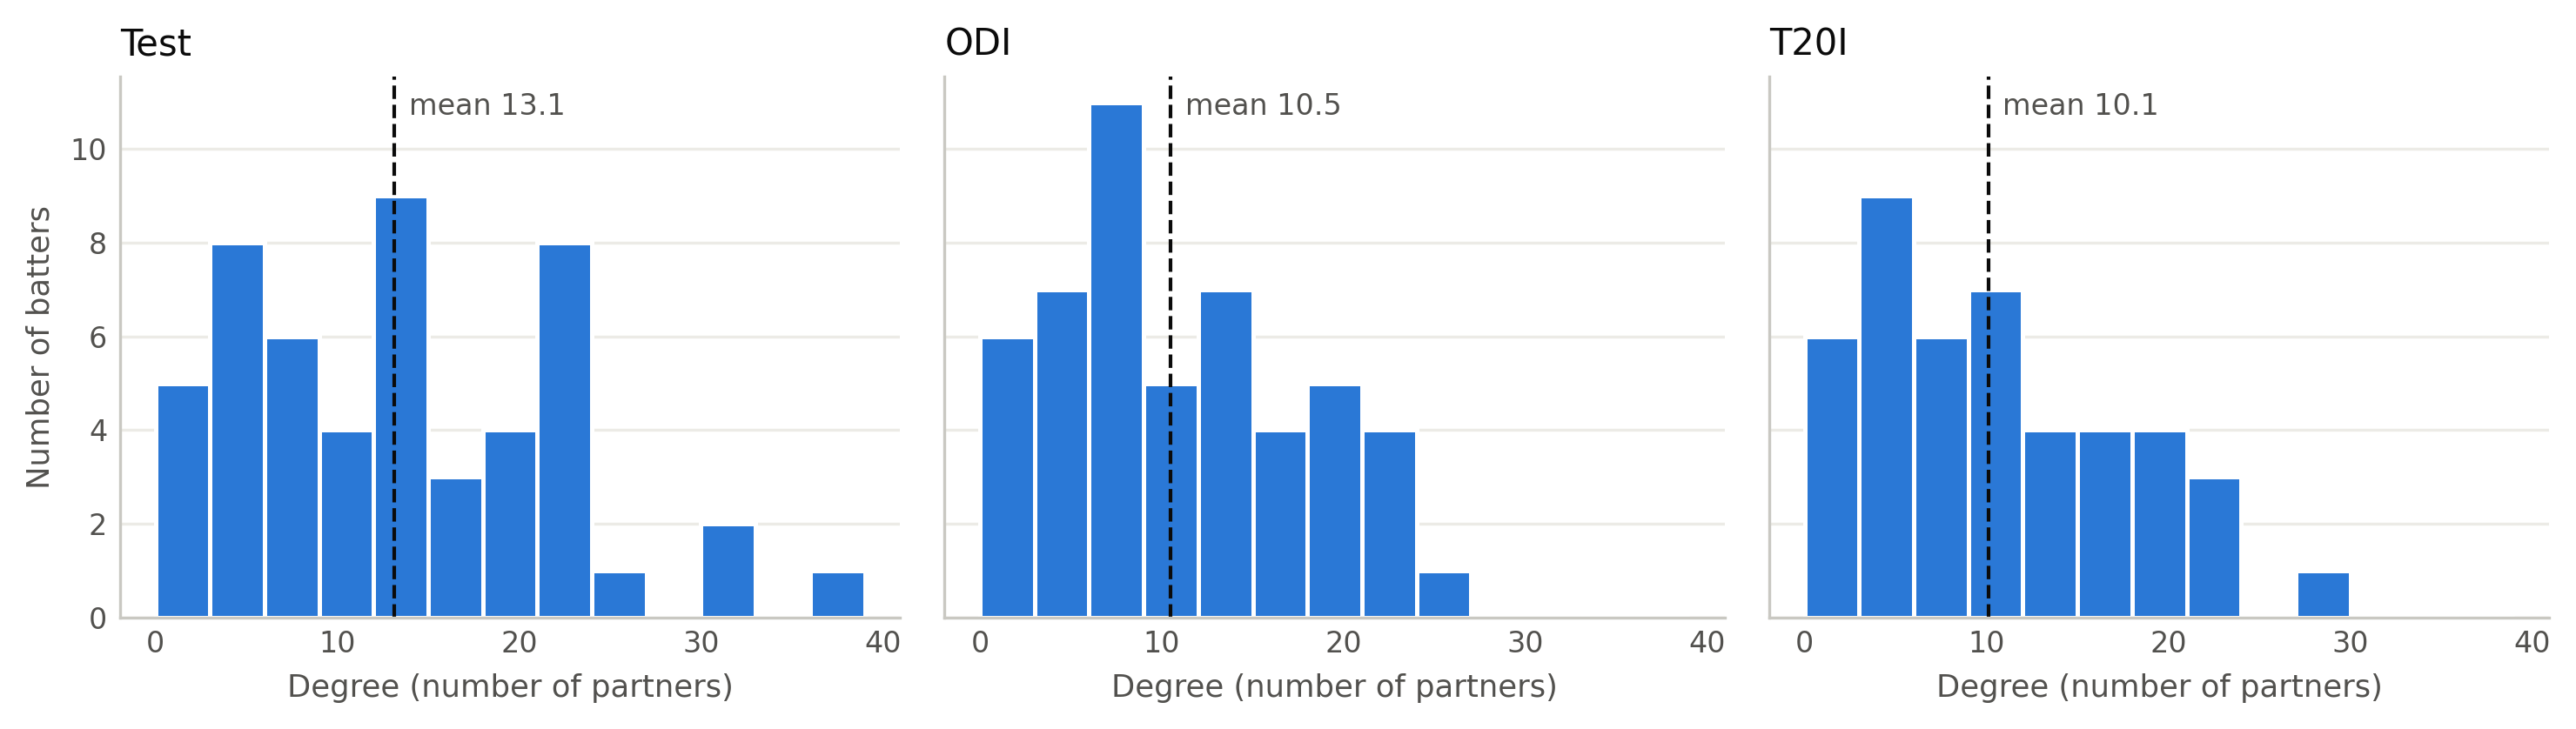

In [3]:
from IPython.display import Image
Image(filename=str(FIGURES_FOLDER / "degree_distributions.png"), width=700)